# Does Money Buy Happiness? GDP per Capita vs Life Satisfaction

**Stack:** Python, pandas, seaborn, scikit-learn

> **Project origin.** Originally completed as a weekly assignment in an Introduction to Machine Learning course (KBTU). This version is restructured as a standalone case study and extended with the additional analysis listed below.

**What this version adds**

- correlation analysis with significance (Pearson and Spearman)
- leave-one-out cross-validation to compare linear regression with KNN honestly on a very small dataset
- a baseline model, error metrics (RMSE, MAE, R2) and an interpretation per 10,000 USD of GDP
- explicit limitations (sample size, extrapolation, correlation vs causation)

## Question

Is higher GDP per capita associated with higher reported life satisfaction, and how well can a simple model predict it?

**Data:** `lifesat.csv` (27 countries: `Country`, `GDP per capita (USD)`, `Life satisfaction`).
Put the CSV in the same folder as this notebook.

In [47]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import Markdown, display
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

df = pd.read_csv("lifesat.csv")
gdp, ls = "GDP per capita (USD)", "Life satisfaction"
df.head()

,Country,GDP per capita (USD),Life satisfaction
0,Russia,26456.388,5.8
1,Greece,27287.083,5.4
2,Turkey,28384.988,5.5
3,Latvia,29932.494,5.9
4,Hungary,31007.768,5.6


## 1. Data overview

In [50]:
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
df.describe()

Shape: (27, 3)
Missing values: 0


,GDP per capita (USD),Life satisfaction
count,27.000,27.000
mean,41564.522,6.567
std,9631.452,0.766
min,26456.388,5.400
25%,33938.289,5.900
50%,41627.129,6.800
75%,49690.580,7.300
max,60235.728,7.600


## 2. Exploring the relationship

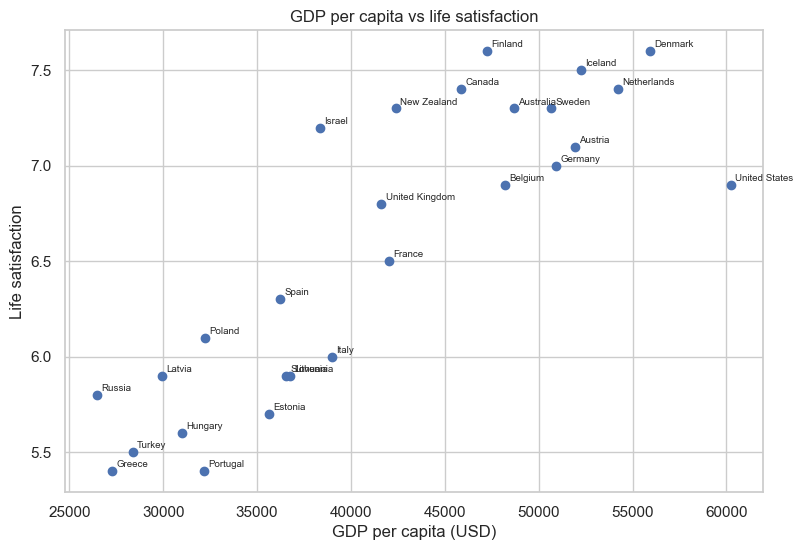

Pearson r  = 0.85 (p = 1.6e-08)
Spearman r = 0.84 (p = 3.2e-08)


In [53]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(df[gdp], df[ls])
for _, row in df.iterrows():
    ax.annotate(row["Country"], (row[gdp], row[ls]), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("GDP per capita (USD)")
ax.set_ylabel("Life satisfaction")
ax.set_title("GDP per capita vs life satisfaction")
plt.show()

pearson_r, pearson_p = stats.pearsonr(df[gdp], df[ls])
spearman_r, spearman_p = stats.spearmanr(df[gdp], df[ls])
print(f"Pearson r  = {pearson_r:.2f} (p = {pearson_p:.1e})")
print(f"Spearman r = {spearman_r:.2f} (p = {spearman_p:.1e})")

## 3. Comparing models

With only 27 countries, a single train/test split would be very unstable. I use **leave-one-out cross-validation**:
each country is predicted by a model that never saw it. A baseline that always predicts the average life satisfaction
shows what any model has to beat.

In [55]:
X = df[[gdp]]
y = df[ls]

models = {"Baseline (mean)": DummyRegressor(strategy="mean"),
          "Linear regression": LinearRegression()}
for k in [1, 3, 5, 10]:
    models[f"KNN (k={k})"] = KNeighborsRegressor(n_neighbors=k)

rows = []
for name, m in models.items():
    pred = cross_val_predict(m, X, y, cv=LeaveOneOut())
    rows.append({"model": name,
                 "RMSE": np.sqrt(mean_squared_error(y, pred)),
                 "MAE": mean_absolute_error(y, pred),
                 "R2": r2_score(y, pred)})
cv_results = pd.DataFrame(rows).set_index("model").sort_values("RMSE")
cv_results

,RMSE,MAE,R2
model,,,
KNN (k=10),0.368,0.312,0.759
KNN (k=5),0.399,0.327,0.718
KNN (k=3),0.425,0.332,0.681
Linear regression,0.429,0.338,0.674
KNN (k=1),0.550,0.459,0.463
Baseline (mean),0.780,0.721,-0.078


## 4. Final model and predictions

Life satisfaction = 3.75 + 6.78e-05 x GDP
Each additional 10,000 USD of GDP per capita is associated with +0.68 points of life satisfaction.


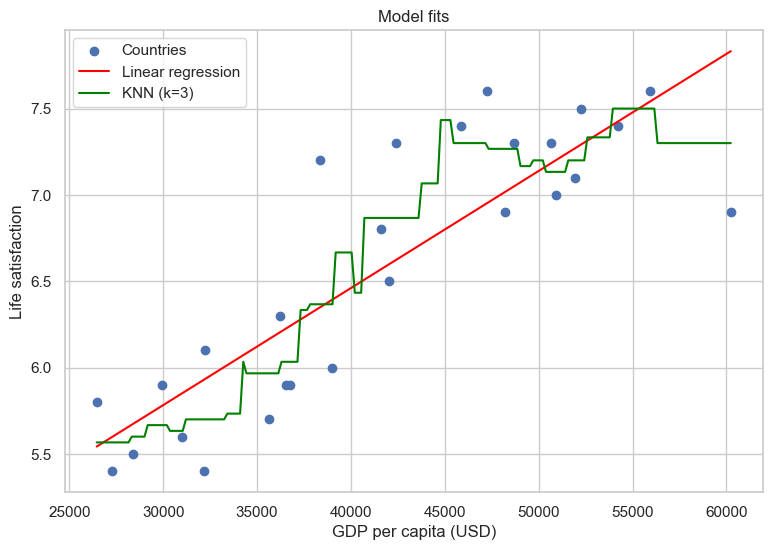

,"Predicted life satisfaction at GDP 37,655 USD"
Baseline (mean),6.57
Linear regression,6.30
KNN (k=1),7.20
KNN (k=3),6.33
KNN (k=5),6.26
KNN (k=10),6.37


In [58]:
final = LinearRegression().fit(X, y)
print(f"Life satisfaction = {final.intercept_:.2f} + {final.coef_[0]:.2e} x GDP")
print(f"Each additional 10,000 USD of GDP per capita is associated with {final.coef_[0] * 10_000:+.2f} points of life satisfaction.")

grid = pd.DataFrame({gdp: np.linspace(df[gdp].min(), df[gdp].max(), 200)})
knn3 = KNeighborsRegressor(n_neighbors=3).fit(X, y)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(X[gdp], y, label="Countries")
ax.plot(grid[gdp], final.predict(grid), color="red", label="Linear regression")
ax.plot(grid[gdp], knn3.predict(grid), color="green", label="KNN (k=3)")
ax.set_xlabel("GDP per capita (USD)")
ax.set_ylabel("Life satisfaction")
ax.set_title("Model fits")
ax.legend()
plt.show()

new = pd.DataFrame({gdp: [37655.2]})
preds = {name: m.fit(X, y).predict(new)[0] for name, m in models.items()}
pd.Series(preds, name="Predicted life satisfaction at GDP 37,655 USD").round(2).to_frame()

## 5. Key findings

In [60]:
strength = "strong" if abs(pearson_r) >= 0.7 else "moderate" if abs(pearson_r) >= 0.4 else "weak"
direction = "positive" if pearson_r > 0 else "negative"
best = cv_results.index[0]
base_rmse = cv_results.loc["Baseline (mean)", "RMSE"]
lr_rmse = cv_results.loc["Linear regression", "RMSE"]

findings = [
    f"- **Relationship:** a {strength} {direction} association between GDP per capita and life satisfaction "
    f"(Pearson r = {pearson_r:.2f}, p = {pearson_p:.1e}; Spearman = {spearman_r:.2f}).",
    f"- **Effect size:** about {final.coef_[0] * 10_000:+.2f} points of life satisfaction per additional 10,000 USD of GDP per capita.",
    f"- **Best model in cross-validation:** {best} (RMSE {cv_results.loc[best, 'RMSE']:.2f}) vs "
    f"{base_rmse:.2f} for the mean baseline.",
    f"- **Model choice:** k was picked using the same cross-validation, which flatters the best KNN slightly. "
    f"Linear regression (RMSE {lr_rmse:.2f}) is close behind and gives an interpretable effect size, "
    "so it is a reasonable default.",
]
display(Markdown("\n".join(findings)))

- **Relationship:** a strong positive association between GDP per capita and life satisfaction (Pearson r = 0.85, p = 1.6e-08; Spearman = 0.84).
- **Effect size:** about +0.68 points of life satisfaction per additional 10,000 USD of GDP per capita.
- **Best model in cross-validation:** KNN (k=10) (RMSE 0.37) vs 0.78 for the mean baseline.
- **Model choice:** k was picked using the same cross-validation, which flatters the best KNN slightly. Linear regression (RMSE 0.43) is close behind and gives an interpretable effect size, so it is a reasonable default.

## 6. Limitations

- Only 27 countries, all with GDP per capita between roughly 26,000 and 60,000 USD. Predictions for much poorer or richer countries would be extrapolation and should not be trusted.
- Correlation is not causation: health, social support and freedom also correlate with both GDP and life satisfaction.
- KNN predictions are step-like and depend heavily on which few neighbours are nearby; with this little data, differences between models are small compared with the noise.